In [1]:
# 실습 준비 ① 설치 — Colab 에서만 설치합니다
#  새로 설치하는 것은 하나입니다 — 교안의 수를 계산한 버전에 맞춰 고정합니다.
#    kiwipiepy 0.23.1 : 한국어 형태소 분석기 Kiwi. 버전을 올리면 문서 비율이 소수 둘째 자리에서 달라질 수 있습니다
#  pandas · numpy · matplotlib 은 Colab 기본 버전을 그대로 씁니다. 그래프의 한글을 위해 나눔 폰트도 여기서 설치합니다.
import shutil
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kiwipiepy==0.23.1"], check=False)
    if shutil.which("apt-get"):
        subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
print("설치 셀 완료 —", "kiwipiepy 0.23.1 · 나눔 폰트를 설치했습니다" if IN_COLAB
      else "Colab 이 아니라 설치를 건너뛰었습니다(kiwipiepy 가 이미 있어야 합니다)")

설치 셀 완료 — Colab 이 아니라 설치를 건너뛰었습니다(kiwipiepy 가 이미 있어야 합니다)


In [2]:
# 실습 준비 ② 환경 확인 — 한글 폰트 · 그림 색 · DEVICE · Kiwi 버전
import glob
import os
import sys
import warnings

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# 한글 폰트 — 설치한 나눔 ttf 를 폰트 목록에 직접 등록합니다.
#  설치는 디스크에 파일만 만듭니다. 이미 떠 있는 폰트 목록은 그 사실을 모르므로 addfont 로
#  등록해야 이름이 보입니다(등록하지 않으면 DejaVu Sans 로 밀려 한글이 전부 □ 로 나옵니다).
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없습니다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색 — 기준 = 남색, 강조 = 하늘색, 문맥 = 회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절합니다

# DEVICE — 이 실습은 모델을 호출하지 않으므로 cpu 여도 됩니다
try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"
print(f"DEVICE : {DEVICE} | 사용 폰트 : {FONT}")
print("이 실습은 cpu 여도 됩니다. 모델을 호출하지 않고 형태소 분석기로 단어만 집계합니다")

import kiwipiepy
print(f"kiwipiepy {kiwipiepy.__version__}")
if kiwipiepy.__version__ != "0.23.1":
    print("참고 — 교안의 수는 kiwipiepy 0.23.1 로 계산했습니다. 다른 버전에서는 문서 비율이 소수 둘째 자리에서 조금 다를 수 있습니다.")

DEVICE : cpu | 사용 폰트 : DejaVu Sans
이 실습은 cpu 여도 됩니다. 모델을 호출하지 않고 형태소 분석기로 단어만 집계합니다
kiwipiepy 0.24.0
참고 — 교안의 수는 kiwipiepy 0.23.1 로 계산했습니다. 다른 버전에서는 문서 비율이 소수 둘째 자리에서 조금 다를 수 있습니다.


표 1 · 별점 1·2점 리뷰 1만 건의 리뷰 수 상위 15 (품사 선택 두 가지)
  명사만      : 배송 · 구매 · 생각 · 제품 · 사용 · 주문 · 맛 · 가격 · 때 · 사이즈 · 부분 · 반품 · 상품 · 불편 · 냄새
  명사 + 용언 : 하다 · 쓰다 · 되다 · 배송 · 같다 · 사다 · 좋다 · 없다 · 구매 · 오다 · 나다 · 있다 · 생각 · 먹다 · 제품
  1위의 리뷰 수 : 명사만 배송 1,097건 · 명사 + 용언 하다 1,840건
  두 목록에 함께 있는 단어 4개 : 배송 · 구매 · 생각 · 제품
표 2 · 국외여행 민원의 사용자 사전 전후 문서 수 (건)
  국외여행 민원 : 13,012건 (시험 입력 · 빈 제목을 뺀 뒤)
  사용자 사전에 더한 단어 : 항공권 · 우한폐렴 · 취소수수료
  취소 : 기본 사전 6,659 → 사용자 사전 6,544
  여행 : 기본 사전 9,371 → 사용자 사전 9,340
  수수료 : 기본 사전 770 → 사용자 사전 614
표 3 · 국외여행 민원의 불용어를 뺀 상위 7 문서 비율 (%, 95% 구간)
  여행   71.78  (71.01～72.55)
  취소   50.29  (49.43～51.15)
  위약금  29.33  (28.54～30.11)
  환불   25.48  (24.74～26.23)
  국외   24.48  (23.74～25.22)
  코로나  19.38  (18.70～20.06)
  해지   19.14  (18.47～19.82)


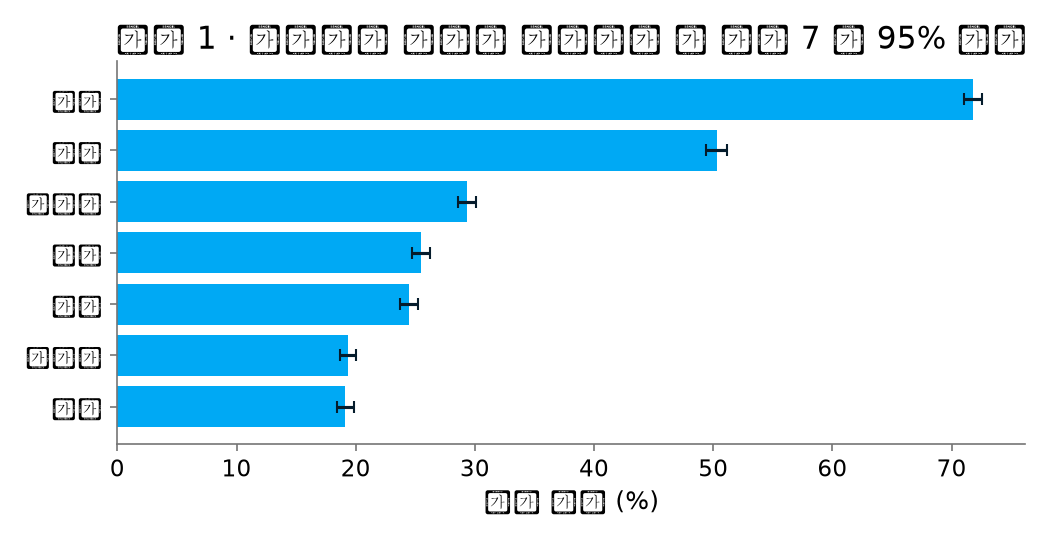

In [3]:
# 오늘의 준비 — 읽고 실행만 합니다
# 리뷰 1만 건과 국외여행 민원으로 표 1～3 과 그림 1 을 만듭니다. 처음 한 번은 원자료를 받느라 1분 안팎 걸립니다
import os, re, time, math, hashlib, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from kiwipiepy import Kiwi

os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")   # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "reviews": ("https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt",
                "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"   # 과정 복제본 — 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def fetch_one(url, name):
    # url 에서 받아 자료 폴더/cache/ 에 두고 경로를 반환함 — 실패하면 세 번까지 다시 시도하고, 끝내 못 받으면 None
    path = os.path.join(data_dir(), "cache", name)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    for i in range(3):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            os.replace(path + ".part", path)
            return path
        except Exception as e:
            print(f"받기 실패 {i + 1}/3: {e}")
            time.sleep(2 * (i + 1))
    return None


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = fetch_one(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:   # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = fetch_one(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def clean_review(text):
    # 리뷰 잡음 정리 — 자음 넷 이상의 자모 나열은 지우고, 같은 자모 반복은 두 글자로 줄이고, 띄어쓰기는 그대로
    text = re.sub(r"[ㄱ-ㅣㆍ]{4,}", lambda m: "" if len(set(re.findall(r"[ㄱ-ㅎ]", m.group()))) >= 4 else m.group(), text)
    text = re.sub(r"([ㄱ-ㅎㅏ-ㅣ])\1{2,}", r"\1\1", text)
    return re.sub(r"\s{2,}", " ", text).strip()


TEST_INPUT_RE = re.compile(   # 민원 파일의 시험 입력 행
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 제목
NOUN_TAGS, PRED_TAGS = ("NNG", "NNP"), ("VV", "VA")   # 명사 · 용언(동사·형용사)
STOPWORDS = ["문의", "요청", "관련", "요구", "건", "후", "상담", "불만", "피해"]   # 이론과 같은 불용어 9개

KIWI = Kiwi(num_workers=2)

# 별점 1·2점 리뷰 무작위 1만 건(시드 0) → Kiwi 한 번으로 명사만 · 명사 + 용언 두 목록 → 리뷰 수 상위 15
rows = [ln.split("\t", 1) for ln in open(fetch_raw("reviews"), encoding="utf-8").read().split("\n") if ln]
reviews = pd.DataFrame(rows, columns=["별점", "본문"])
low = reviews[reviews["별점"].astype(int).isin([1, 2])].sample(n=10000, random_state=0)
noun_only, noun_pred = [], []
for toks in KIWI.tokenize(low["본문"].map(clean_review).tolist()):
    tags = [(t.form, t.tag.split("-")[0]) for t in toks]   # 태그는 「-」 앞만 본다(VA-I → VA)
    noun_only.append({f for f, g in tags if g in NOUN_TAGS})
    noun_pred.append({f + ("다" if g in PRED_TAGS else "") for f, g in tags if g in NOUN_TAGS + PRED_TAGS})


def top_k(sets, k):
    # 단어마다 그 단어를 쓴 문서 수 → 많은 차례 k 개(같은 수는 가나다 차례)
    cnt = Counter(w for s in sets for w in s)
    return sorted(cnt.items(), key=lambda x: (-x[1], x[0]))[:k]


top_noun, top_pred = top_k(noun_only, 15), top_k(noun_pred, 15)
shared = [w for w, _ in top_noun if w in {v for v, _ in top_pred}]

print("표 1 · 별점 1·2점 리뷰 1만 건의 리뷰 수 상위 15 (품사 선택 두 가지)")
print("  명사만      :", " · ".join(w for w, _ in top_noun))
print("  명사 + 용언 :", " · ".join(w for w, _ in top_pred))
print(f"  1위의 리뷰 수 : 명사만 {top_noun[0][0]} {top_noun[0][1]:,}건 · 명사 + 용언 {top_pred[0][0]} {top_pred[0][1]:,}건")
print(f"  두 목록에 함께 있는 단어 {len(shared)}개 : {' · '.join(shared)}")

# 국외여행 민원 전체 → 기본 사전 Kiwi 와 사용자 사전 세 단어를 더한 Kiwi 로 같은 제목을 나눔
raw = pd.read_csv(fetch_raw("complaints"), encoding="cp949", dtype=str)
raw = raw.rename(columns=lambda c: c.split("(")[0].strip())
title = raw["사건제목"].fillna("").str.strip()
is_test = title.str.contains(TEST_INPUT_RE)
keep = ~is_test & ~(title.str.match(EMPTY_TITLE_RE) & ~is_test)
trip = title[keep & (raw["품목명"] == "국외여행")].tolist()
n_trip = len(trip)
USER_WORDS = ["항공권", "우한폐렴", "취소수수료"]
kiwi_user = Kiwi(num_workers=2)
for w in USER_WORDS:
    kiwi_user.add_user_word(w, "NNG")
count_base = Counter(w for toks in KIWI.tokenize(trip) for w in {t.form for t in toks if t.tag in NOUN_TAGS})
count_user = Counter(w for toks in kiwi_user.tokenize(trip) for w in {t.form for t in toks if t.tag in NOUN_TAGS})

print("표 2 · 국외여행 민원의 사용자 사전 전후 문서 수 (건)")
print(f"  국외여행 민원 : {n_trip:,}건 (시험 입력 · 빈 제목을 뺀 뒤)")
print(f"  사용자 사전에 더한 단어 : {' · '.join(USER_WORDS)}")
for w in ["취소", "여행", "수수료"]:
    print(f"  {w} : 기본 사전 {count_base[w]:,} → 사용자 사전 {count_user[w]:,}")

# 사용자 사전 뒤의 문서 수 → 불용어를 뺀 상위 7 의 문서 비율과 95% 구간
top7 = [(w, k) for w, k in sorted(count_user.items(), key=lambda x: (-x[1], x[0])) if w not in STOPWORDS][:7]
share = {w: 100 * k / n_trip for w, k in top7}
half = {w: 100 * 1.96 * math.sqrt((k / n_trip) * (1 - k / n_trip) / n_trip) for w, k in top7}
print("표 3 · 국외여행 민원의 불용어를 뺀 상위 7 문서 비율 (%, 95% 구간)")
for w, k in top7:
    print(f"  {w:<4} {share[w]:5.2f}  ({share[w] - half[w]:.2f}～{share[w] + half[w]:.2f})")

fig, ax = plt.subplots(figsize=(7.0, 3.6))
words7 = [w for w, _ in top7]
ax.barh(words7, [share[w] for w in words7], xerr=[half[w] for w in words7], color="#00A9F4", ecolor="#051C2C", capsize=3)
ax.invert_yaxis()
ax.set_xlabel("문서 비율 (%)")
ax.set_title("그림 1 · 국외여행 민원의 불용어를 뺀 상위 7 과 95% 구간")
plt.show()

「환불」을 두 번 쓴 제목이 있을 때의 문서 비율
예를 들어 민원 제목 1,000건 가운데 「환불」을 한 번 쓴 제목이 150건, 두 번 쓴 제목이 10건이라고 합시다. 「환불」의 문서 비율은 얼마일까요?

B 16%: 「환불」을 쓴 제목 160 ÷ 1,000

문서 비율은 그 단어를 쓴 문서 수를 전체 문서 수로 나눈 값입니다. 「환불」을 두 번 쓴 제목도 「환불」을 쓴 문서 한 건입니다. 그래서 문서 수는 150 + 10 = 160건이고, 문서 비율은 160 ÷ 1,000 = 16% 입니다.

17%: 나온 횟수 150 + 10 × 2 = 170 으로 구한 토큰 빈도입니다. 두 번 쓴 제목이 두 번 집계되어, 몇 건이 썼는지를 나타내지 않습니다.
15%: 두 번 쓴 제목 10건을 뺐습니다. 이 제목들도 「환불」을 쓴 제목입니다.
그래서 코드에서는 제목마다 명사 목록을 set 으로 바꾼 뒤 문서 수를 집계합니다. 95% 구간도 이렇게 구한 문서 비율로 계산합니다.

핵심 키워드: 문서 비율 = 그 단어를 쓴 문서 수 ÷ 전체 문서 수, 토큰 빈도와 다름, set 으로 한 문서를 한 번만

「배송비」가 든 제목은 배송 문서인가
예를 들어 민원 제목 「배송비 환불 요청」이 있습니다. 「배송」의 문서 수를 구할 때 이 제목도 포함할까요? 제목 글자에 「배송」이 있는지로 집계할 때와 형태소 명사로 집계할 때를 비교해 이유를 적어 보세요.

배송비 환불 요청의 경우 어절로 나누었을 때 배송비로 분류되고 배송으로는 집계되지 않을 것 같습니다.
형태로소 집계해야지 배송, 비로 나눠져 집계될 것 같습니다.

포함하지 않습니다. 글자로 집계하면 「배송비」 안의 「배송」까지 들어갑니다. 형태소 명사로는 「배송비」 한 단어라 배송 문서가 아닙니다.

Kiwi 는 이 제목을 배송비 · 환불 · 요청 세 명사로 나눕니다. 명사 목록에 「배송」이 없으니 형태소로 집계하면 배송 문서가 아닙니다. 제목 글자에 「배송」이 있는지로 집계하면 「배송비」 · 「오배송」 안의 글자까지 들어갑니다. 그만큼 문서 수가 커집니다.

그래서 단어의 문서 수는 형태소 명사 목록으로 집계합니다. 새 단어를 집계할 때는 원문 몇 건을 읽어 분석기가 나눈 모양을 확인합니다.

모범 답: 「포함하지 않는다. 글자로 집계하면 배송비 안의 배송까지 들어가지만, Kiwi 는 배송비를 한 명사로 나누므로 형태소로는 배송 문서가 아니다.」

채점할 때 볼 것

① 이 제목을 배송 문서에 포함하지 않는다고 적었는가

② 글자로 집계하면 다른 명사 안의 「배송」까지 들어간다고 적었는가

③ 근거로 Kiwi 가 「배송비」를 한 명사로 나눈다고 적었는가

핵심 키워드: 글자 포함 = 다른 명사 안의 글자까지 집계, 형태소 명사 목록, 원문으로 확인

리뷰의 불만 대상을 볼 품사 선택
「오늘의 준비」 셀을 실행하면 나오는 「표 1 · 별점 1·2점 리뷰 1만 건의 리뷰 수 상위 15 (품사 선택 두 가지)」를 봅니다. 리뷰가 무엇에 대한 불만인지 보려면 어느 목록을 쓸까요?

A 명사만: 맛 · 가격 · 사이즈처럼 불만의 대상이 드러난다

불만의 대상은 명사로 나타납니다. 표 1 에서 두 목록에 함께 있는 단어는 배송 · 구매 · 생각 · 제품 4개뿐입니다. 상위 15 가운데 11개가 바뀌었습니다. 명사 + 용언 목록에 새로 든 하다 · 쓰다 · 되다 · 같다로는 무엇에 대한 말인지 알 수 없습니다. 명사만 목록의 맛 · 가격 · 사이즈 · 반품 · 냄새는 불만의 대상이 될 수 있는 단어입니다.

명사 + 용언: 「하다」는 1,874건으로 가장 많지만 무엇을 했는지는 남지 않습니다. 리뷰 수가 많다고 질문에 답하는 단어는 아닙니다.
어느 쪽이든 같다: 함께 있는 단어는 4개이고 11개가 바뀌었습니다. 품사 선택이 순위를 바꿉니다.
그래서 무엇에 대한 불만인지 볼 때는 명사만 남깁니다. 맛 · 가격 같은 후보는 원문 몇 건으로 확인합니다.

핵심 키워드: 품사 선택이 순위를 바꾼다, 불만의 대상은 명사, 후보는 원문으로 확인

사용자 사전을 더한 뒤 바뀐 문서 수
「오늘의 준비」 셀을 실행하면 나오는 「표 2 · 국외여행 민원의 사용자 사전 전후 문서 수 (건)」를 봅니다. 사전에 더하지 않은 「취소」와 「여행」의 문서 수도 바뀌었습니다. 이 결과로 쓸 수 있는 문장은 무엇일까요?

C 사전은 같은 제목의 다른 단어도 바꾸니 수와 사전 목록을 함께 적는다


Kiwi 는 제목 하나를 통째로 분석해 나누는 모양을 정합니다. 표 2 에서 「취소수수료」를 한 단어로 더하자 「취소」는 6,670건에서 6,555건으로 줄었습니다. 그 제목의 명사 목록에 「취소」 대신 「취소수수료」가 남기 때문입니다. 「우한폐렴」을 더하자 같은 제목의 「해외여행」이 해외 · 여행으로 나뉘어, 「여행」은 8,898건에서 8,929건으로 늘었습니다.

우연이다: 같은 제목을 두 번 나눴을 뿐이라 표본은 그대로입니다. 차이는 사전에서 나옵니다.
불용어: 불용어 9개에 「취소」는 없습니다. 표 3 에서도 「취소」는 2위로 남아 있습니다.
그래서 키워드 표의 수는 분석 설정과 함께 읽습니다. 표 아래에 Kiwi 버전과 사용자 사전 목록을 적어 두면 같은 수를 다시 구할 수 있습니다.

핵심 키워드: 사용자 사전은 더하지 않은 단어의 수도 바꾼다, 분모는 그대로, 수와 분석 설정을 함께 적는다

코로나와 해지 가운데 더 많이 말하는 쪽
「오늘의 준비」 셀을 실행하면 나오는 「표 3 · 국외여행 민원의 불용어를 뺀 상위 7 문서 비율 (%, 95% 구간)」을 봅니다. 「코로나」와 「해지」는 어떻게 적을까요?

B 둘 다 약 19% 로 비슷하다: 두 95% 구간이 크게 겹친다

두 단어의 차이가 오차 한계보다 작으면 차례를 정하지 않습니다. 표 3 에서 「코로나」는 19.43%(18.75～20.11), 「해지」는 19.20%(18.52～19.87)입니다. 차이는 0.23%p 이고 오차 한계는 약 0.68%p 입니다. 그림 1 에서도 두 오차 막대가 대부분 겹칩니다.

코로나가 더 많다: 30건은 0.23%p 차이입니다. 구간은 이 수가 이만큼 달라질 수 있다는 범위라 차례가 바뀔 수 있습니다.
적을 수 없다: 문서 비율은 문서마다 0 또는 1 인 값의 평균입니다. 그래서 전체 건수로도 구간을 구할 수 있습니다.
그래서 키워드 표에는 「코로나 · 해지는 둘 다 약 19%」처럼 적습니다. 문서 비율은 95% 구간과 함께 읽습니다.

핵심 키워드: 문서 비율의 95% 구간, 구간이 겹치면 차례를 정하지 않음, 0 또는 1 의 평균

**1. 기본값 읽기 오류**: UnicodeDecodeError ('utf-8' codec can't decode byte 0xbb in position 0: invalid start byte)
민원 원본 499,999행 → 시험 입력 91행·빈 제목 64행 제거 → 499,844행, 전화번호 형태 가림 10행
**2. 민원 행 수**: 499,844행
**3. 환불 문서 비율**: 17.73% (3,545건 / 20,000건)
**4. 원문 9건**
원문 [문의] 행 41074 · 심의 절차 문의
원문 [문의] 행 125780 · 태양열 설치 후 A/S 출장비 문의
원문 [문의] 행 281417 · 아들 게임결제 환불 문의
원문 [환불] 행 281417 · 아들 게임결제 환불 문의
원문 [환불] 행 281756 · 천식 치료약 변경후 부작용으로 약변경하는 경우 기존처방약 환불 문의
원문 [환불] 행 219354 · 사업자 귀책 헬스장 환불 기준 문의
원문 [요청] 행 496520 · 패딩점포 이염에 배상요청
원문 [요청] 행 491196 · 연습실 음식섭취로 대관료의 2배 요청하여 문의
원문 [요청] 행 42604 · 자동차 주차자장에서 발생한 접촉사고 처리 지연에 대한 해결 요청


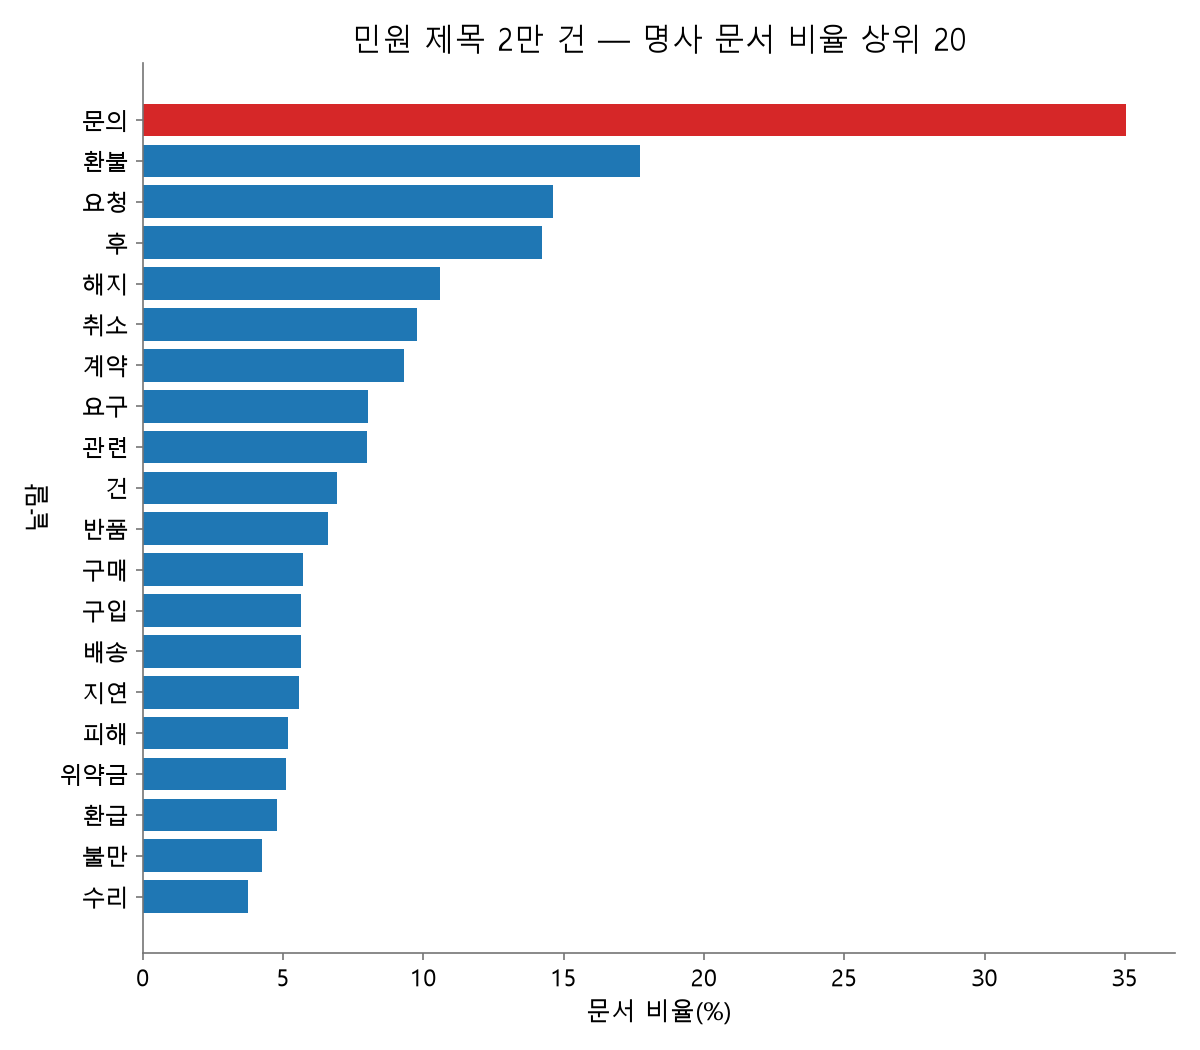

In [ ]:
# 미션 1 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 1 에 쓸 이름을 직접 만듭니다
#  과정 복제본(원 출처와 같은 바이트)에서 민원 파일을 받아 두고(처음 한 번만), 읽기 · 표본 · 형태소 함수를 만듭니다.
#  표를 읽거나 형태소를 세지는 않습니다 — 그 일은 PROMPT 셀에서 합니다. 받은 뒤에는 1초 안팎입니다
import hashlib
import math
import os
import re
import time
import urllib.request
from decimal import ROUND_HALF_UP, Decimal

import pandas as pd
from kiwipiepy import Kiwi

# ---------------------------------------------------------------- 원 출처 (조회 2026-09-24)
RAW_COMPLAINTS_URL = ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                      "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N")
RAW_REVIEWS_URL = "https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt"
RAW_FILES = {  # 이름: (원 출처 URL, 내 컴퓨터에 둘 파일 이름, 교안의 수를 계산한 파일의 SHA-256, 데이터 페이지)
    "complaints": (RAW_COMPLAINTS_URL, "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
    "reviews": (RAW_REVIEWS_URL, "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳
SUBDIRS = ("", "cache", "raw", "processed")  # 자료 폴더 아래에서 찾는 순서


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    # 파일의 SHA-256 16진 문자열 — 받은 파일이 교안의 파일과 같은지 대조합니다
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True (실패하면 세 번까지 다시 시도)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:  # network error: retry
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name):
    # 자료 폴더에 있으면 그 경로, 없으면 url 에서 받아 자료 폴더/cache/ 에 두고 경로를 반환합니다(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        print(f"{name} 을 받습니다 (처음 한 번만)")
        if not _download(url, path):
            return None
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 자료 폴더를 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받습니다
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 교안의 파일과 다르면 지우고 원 출처에서 받습니다
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


# ---------------------------------------------------------------- 반올림 (교안의 수와 같게)
def rnd(x, digits):
    # 십진 값 기준 반올림(마지막 숫자가 5 면 올림) — 파이썬 round 는 4.045 를 4.04 로 적습니다
    x = float(x)
    if not math.isfinite(x):
        return x
    return float(Decimal(f"{x:.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


def pct2(k, n, digits=2):
    # 문서 k 건 ÷ 전체 n 건을 백분율로, 소수 둘째 자리: pct2(809, 20000) -> 4.05
    return rnd(100 * k / n, digits)


def half95(k, n, digits=2):
    # 비율 k/n 의 95% 구간 오차 한계(구간 길이의 절반, ± 뒤의 값)를 %p 로: 1.96 × √(p̂(1 − p̂)/n) × 100
    p = k / n
    return rnd(100 * 1.96 * math.sqrt(p * (1 - p) / n), digits)


# ---------------------------------------------------------------- 민원 파일 읽기
# 상담 시스템에 시험 삼아 입력한 행(소비자 민원이 아님)을 찾는 정규식
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")  # 한글 음절도 로마자도 없는 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")  # 전화번호 형태
PHONE_MASK = "[전화번호]"  # 원 출처가 이미 가린 번호와 같은 표지


def mask_phones(text):
    # 전화번호 형태를 [전화번호] 로 가림
    return PHONE_RE.sub(PHONE_MASK, text)


def tidy_columns(df):
    # 열 이름 정리: '사건제목(ACCIDENT_TITLE)' -> '사건제목'
    return df.rename(columns=lambda c: c.split("(")[0].strip())


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기: 시험 입력·빈 제목 행 제거, 전화번호 형태 가림, 열 이름 정리, 날짜 변환
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = tidy_columns(raw)
    df.insert(0, "row_id", range(len(df)))  # 원 파일의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(mask_phones)
    df["번호가림"] = df["사건제목"].ne(title)  # 전화번호 형태를 가린 행이면 True
    df["접수일자"] = pd.to_datetime(df["접수일자"], format="%Y-%m-%d")
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 제목 {int(is_empty.sum())}행 제거 "
              f"→ {len(df):,}행, 전화번호 형태 가림 {int(df['번호가림'].sum())}행")
    return df


# ---------------------------------------------------------------- 표본과 형태소
def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력 행과 같은 seed 면 같은 행이 같은 순서로 나옵니다
    return df.sample(n=n, random_state=seed)


NOUN_TAGS = ("NNG", "NNP")  # 일반 명사 + 고유 명사 (Kiwi 기본 사전)


def kiwi_nouns(texts, kiwi):
    # 문서마다 명사(NNG·NNP) 목록 — 나온 순서와 반복을 그대로 둡니다(문서 수를 집계할 때는 set 으로)
    return [[t.form for t in toks if t.tag in NOUN_TAGS] for toks in kiwi.tokenize(list(texts))]


COMPLAINTS_PATH = fetch_raw("complaints")   # 쓸 이름 — 민원 원본 파일 경로 (cp949)
import os
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
KIWI = Kiwi(num_workers=2)                  # 쓸 이름 — 형태소 분석기(기본 사전, 작업자 2)
print(f"민원 원본 : {os.path.basename(COMPLAINTS_PATH)} · {os.path.getsize(COMPLAINTS_PATH):,} 바이트")
print("쓸 수 있는 이름 : COMPLAINTS_PATH · read_complaints · sample_rows · kiwi_nouns · KIWI · pct2")

미션 1 의 완성 코드는 제목마다 명사 목록을 set 으로 바꾼 뒤 낱말마다 문서 수를 집계합니다. set 을 빼고 집계하면 무엇을 집계하게 되나요?

A. 토큰 빈도: 한 제목이 같은 명사를 두 번 쓰면 2 가 된다

토큰 빈도입니다. set 은 한 제목 안에서 겹친 낱말을 하나만 남기므로, 빼고 집계하면 「환불」을 두 번 쓴 제목이 2 로 더해집니다. 즉 문서 수 대신 「몇 번 나왔는가」(토큰 빈도)를 구하게 됩니다(이론 「5. 토큰 빈도와 문서 비율」).

「환불」은 표본 2만 건에서 토큰 빈도 3,658, 문서 수 3,550 입니다. 같은 제목 안에서 두 번째 이상으로 나온 「환불」이 3,658 − 3,550 = 108번입니다. 토큰 빈도를 제목 수로 나눈 3,658 ÷ 20,000 = 18.29% 는 「환불」을 쓴 제목의 비율이 아닙니다. 그래서 이 값으로는 95% 구간을 구하지 않습니다. 문서 비율은 3,550 ÷ 20,000 = 17.75% 입니다.

문서 수 그대로: 한 제목이 같은 명사를 두 번 쓰는 일이 없을 때만 맞습니다. 「환불」은 108번 겹쳐 나와 두 값이 다릅니다.
어절 수: kiwi_nouns 가 이미 형태소 명사 목록을 만들었으므로 어절은 집계에 쓰이지 않습니다. 어절 일치는 공백으로 자른 어절이 「환불」과 똑같은 제목만 집계합니다. 이렇게 구한 값 10.48% 는 따로 나옵니다.
문서 비율을 내려면 제목마다 set 으로 바꾼 뒤 문서 수를 구합니다. 분모는 제목 수 20,000 입니다.

핵심 키워드: 문서 비율 = 그 낱말을 쓴 문서 수 ÷ 전체 문서 수, set 으로 한 문서를 한 번만, 토큰 빈도 ≥ 문서 수

In [4]:
# 미션 2 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 2 에 쓸 이름을 직접 만듭니다
#  미션 1 과 같은 함수로 민원 파일을 읽고, 같은 표본 2만 건(시드 0)과 그 명사 목록을 다시 만듭니다.
#  앞 미션의 결과에 기대지 않습니다. 원자료를 받아 둔 뒤에는 5초 안팎입니다(읽기 2초 · 형태소 분석 2만 건 2.5초)
import hashlib
import math
import os
import re
import time
import urllib.request
from decimal import ROUND_HALF_UP, Decimal

import pandas as pd
from kiwipiepy import Kiwi

# ---------------------------------------------------------------- 원 출처 (조회 2026-09-24)
RAW_COMPLAINTS_URL = ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                      "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N")
RAW_REVIEWS_URL = "https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt"
RAW_FILES = {  # 이름: (원 출처 URL, 내 컴퓨터에 둘 파일 이름, 교안의 수를 계산한 파일의 SHA-256, 데이터 페이지)
    "complaints": (RAW_COMPLAINTS_URL, "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
    "reviews": (RAW_REVIEWS_URL, "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳
SUBDIRS = ("", "cache", "raw", "processed")  # 자료 폴더 아래에서 찾는 순서


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    # 파일의 SHA-256 16진 문자열 — 받은 파일이 교안의 파일과 같은지 대조합니다
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True (실패하면 세 번까지 다시 시도)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:  # network error: retry
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name):
    # 자료 폴더에 있으면 그 경로, 없으면 url 에서 받아 자료 폴더/cache/ 에 두고 경로를 반환합니다(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        print(f"{name} 을 받습니다 (처음 한 번만)")
        if not _download(url, path):
            return None
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 자료 폴더를 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받습니다
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 교안의 파일과 다르면 지우고 원 출처에서 받습니다
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


# ---------------------------------------------------------------- 반올림 (교안의 수와 같게)
def rnd(x, digits):
    # 십진 값 기준 반올림(마지막 숫자가 5 면 올림) — 파이썬 round 는 4.045 를 4.04 로 적습니다
    x = float(x)
    if not math.isfinite(x):
        return x
    return float(Decimal(f"{x:.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


def pct2(k, n, digits=2):
    # 문서 k 건 ÷ 전체 n 건을 백분율로, 소수 둘째 자리: pct2(809, 20000) -> 4.05
    return rnd(100 * k / n, digits)


def half95(k, n, digits=2):
    # 비율 k/n 의 95% 구간 오차 한계(구간 길이의 절반, ± 뒤의 값)를 %p 로: 1.96 × √(p̂(1 − p̂)/n) × 100
    p = k / n
    return rnd(100 * 1.96 * math.sqrt(p * (1 - p) / n), digits)


# ---------------------------------------------------------------- 민원 파일 읽기
# 상담 시스템에 시험 삼아 입력한 행(소비자 민원이 아님)을 찾는 정규식
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")  # 한글 음절도 로마자도 없는 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")  # 전화번호 형태
PHONE_MASK = "[전화번호]"  # 원 출처가 이미 가린 번호와 같은 표지


def mask_phones(text):
    # 전화번호 형태를 [전화번호] 로 가림
    return PHONE_RE.sub(PHONE_MASK, text)


def tidy_columns(df):
    # 열 이름 정리: '사건제목(ACCIDENT_TITLE)' -> '사건제목'
    return df.rename(columns=lambda c: c.split("(")[0].strip())


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기: 시험 입력·빈 제목 행 제거, 전화번호 형태 가림, 열 이름 정리, 날짜 변환
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = tidy_columns(raw)
    df.insert(0, "row_id", range(len(df)))  # 원 파일의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(mask_phones)
    df["번호가림"] = df["사건제목"].ne(title)  # 전화번호 형태를 가린 행이면 True
    df["접수일자"] = pd.to_datetime(df["접수일자"], format="%Y-%m-%d")
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 제목 {int(is_empty.sum())}행 제거 "
              f"→ {len(df):,}행, 전화번호 형태 가림 {int(df['번호가림'].sum())}행")
    return df


# ---------------------------------------------------------------- 표본과 형태소
def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력 행과 같은 seed 면 같은 행이 같은 순서로 나옵니다
    return df.sample(n=n, random_state=seed)


NOUN_TAGS = ("NNG", "NNP")  # 일반 명사 + 고유 명사 (Kiwi 기본 사전)


def kiwi_nouns(texts, kiwi):
    # 문서마다 명사(NNG·NNP) 목록 — 나온 순서와 반복을 그대로 둡니다(문서 수를 집계할 때는 set 으로)
    return [[t.form for t in toks if t.tag in NOUN_TAGS] for toks in kiwi.tokenize(list(texts))]


COMPLAINTS_PATH = fetch_raw("complaints")   # 민원 원본 파일 경로 (cp949)
import os
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
KIWI = Kiwi(num_workers=2)                  # 형태소 분석기(기본 사전, 작업자 2)

# 쓸 이름 — 미션 1 과 같은 표본 2만 건(시드 0)과, 행 순서가 같은 명사 목록
C20K = sample_rows(read_complaints(COMPLAINTS_PATH), 20000, seed=0)[["row_id", "품목명", "사건제목"]]
C20K = C20K.reset_index(drop=True)
NOUNS_20K = kiwi_nouns(C20K["사건제목"], KIWI)   # NOUNS_20K[i] = C20K 의 i 번째 제목의 명사 목록
FIVE_WORDS = ["환불", "해지", "위약금", "배송", "취소"]   # 전임 담당자가 비교한 다섯 낱말

print(f"표본 C20K : {len(C20K):,}건 · 열 {list(C20K.columns)}")
print(f"명사 목록 NOUNS_20K : {len(NOUNS_20K):,}개 — 첫 제목 「{C20K['사건제목'][0]}」 → {NOUNS_20K[0]}")
print("준비 완료 — C20K · NOUNS_20K · FIVE_WORDS · pct2 · KIWI · kiwi_nouns · read_complaints · sample_rows")

민원 원본 499,999행 → 시험 입력 91행·빈 제목 64행 제거 → 499,844행, 전화번호 형태 가림 10행
표본 C20K : 20,000건 · 열 ['row_id', '품목명', '사건제목']
명사 목록 NOUNS_20K : 20,000개 — 첫 제목 「심의 절차 문의」 → ['심의', '절차', '문의']
준비 완료 — C20K · NOUNS_20K · FIVE_WORDS · pct2 · KIWI · kiwi_nouns · read_complaints · sample_rows


민원 제목 표본 20,000건 · 다섯 낱말의 문서 비율
  환불 · 10.48 %
  해지 · 3.52 %
  위약금 · 4.05 %
  배송 · 1.36 %
  취소 · 4.64 %
판단 : 위약금 민원(4.05%)이 해지 민원(3.52%)보다 많다


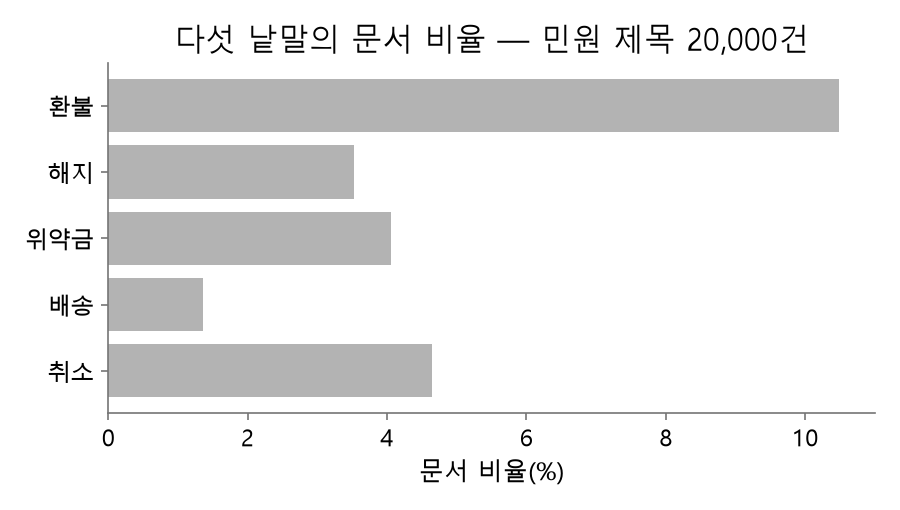

In [10]:
# 미션 2 — 프롬프트 (함정)   # ai: prompt
# 이 미션은 함정입니다 — 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 출력한 표로 내린 결론은 믿을 수 없습니다.
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 튜터가 AI 코드 표시선 아래를 다시 씁니다.
# 따옴표 안이 비어 있으면 아래 코드의 채점만 나오고 완성본 풀이는 잠깁니다
PROMPT = """
이 미션의 질문: 전임 담당자는 위약금 4.05%, 해지 3.52% 를 근거로 「위약금 민원이 해지 민원보다 많다」고 결론 내렸습니다. 같은 표본 2만 건을 형태소 명사로 다시 집계하면 두 낱말의 순위는 어떻게 될까요?


"""
# --- 여기부터 AI 코드 ---
# ↓ 전임 담당자의 코드 — 이 코드가 만든 표로 「위약금 민원이 해지 민원보다 많다」고 판단했습니다. 그대로 실행하면 채점이 ❌ 를 냅니다
titles = C20K["사건제목"]
share = {w: pct2(sum(w in t.split() for t in titles), len(C20K)) for w in FIVE_WORDS}   # 낱말마다 그 낱말을 쓴 제목의 비율
print(f"민원 제목 표본 {len(C20K):,}건 · 다섯 낱말의 문서 비율")
for w in FIVE_WORDS:
    print(f"  {w} · {share[w]:.2f} %")
print(f"판단 : 위약금 민원({share['위약금']:.2f}%)이 해지 민원({share['해지']:.2f}%)보다 많다")

fig, ax = plt.subplots(figsize=(FIG_W * 0.6, 3.4))
ax.barh(FIVE_WORDS, [share[w] for w in FIVE_WORDS], color=COL["연회색"])
ax.invert_yaxis()
ax.set_xlabel("문서 비율(%)")
ax.set_title(f"다섯 낱말의 문서 비율 — 민원 제목 {len(C20K):,}건")
plt.show()

민원 제목 표본 20,000건 · 다섯 낱말의 문서 비율
  환불 · 어절 10.48 % · 형태소 17.73 %
  해지 · 어절 3.52 % · 형태소 10.58 %
  위약금 · 어절 4.05 % · 형태소 5.10 %
  배송 · 어절 1.36 % · 형태소 5.63 %
  취소 · 어절 4.64 % · 형태소 9.79 %
해지 형태소 비율 = 10.58 %
위약금 형태소 비율 = 5.10 %
배송 형태소 비율 = 5.63 %
형태소 순위 : 해지 > 위약금
판단 : 해지 민원(10.58%)이 위약금 민원(5.10%)보다 많다


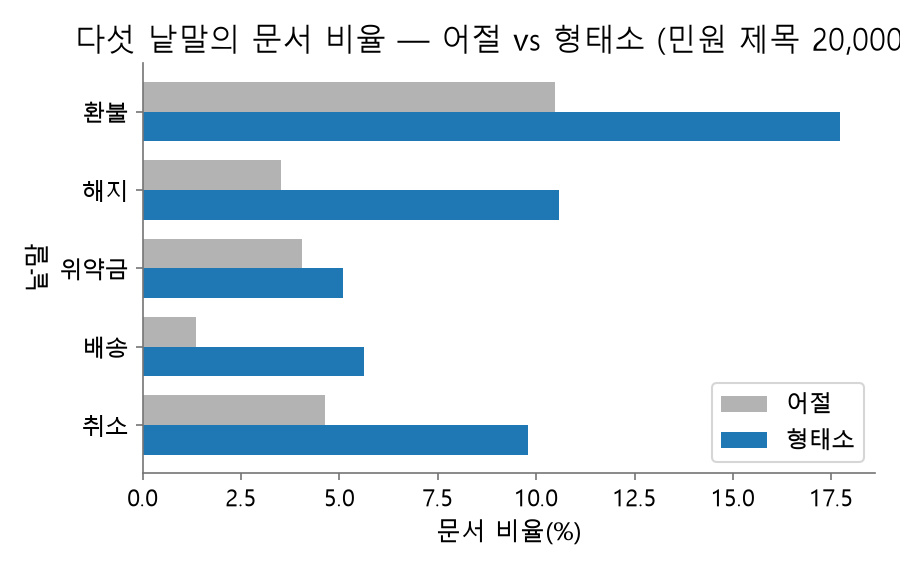

In [11]:
#진짜 문제는 w in t.split()입니다. 어절 전체가 낱말과 똑같아야 맞기 때문에 「해지를」「해지요청」「해지하고」는 모두 빠집니다. 한국어는 조사와 어미가 붙어서, 낱말마다 빠지는 정도가 다릅니다. 그래서 두 낱말의 순위가 뒤집힐 수 있습니다. 이 틀린 곳이 「집계 방법 하나」입니다. 단위가 어절에서 형태소 명사로 바뀌는 것이고, 분모와 한 제목 한 번 세기는 그대로입니다.

# 미션 2 — 프롬프트 (함정)   # ai: prompt
# 이 미션은 함정입니다 — 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 출력한 표로 내린 결론은 믿을 수 없습니다.
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 튜터가 AI 코드 표시선 아래를 다시 씁니다.
# 따옴표 안이 비어 있으면 아래 코드의 채점만 나오고 완성본 풀이는 잠깁니다
PROMPT = """
이 미션의 질문: 전임 담당자는 위약금 4.05%, 해지 3.52% 를 근거로 「위약금 민원이 해지 민원보다 많다」고 결론 내렸습니다. 같은 표본 2만 건을 형태소 명사로 다시 집계하면 두 낱말의 순위는 어떻게 될까요?
내 생각: 아래 전임자 코드는 문서 비율을 추출해야하는데 한 단어가 얼마나 입력되었는지를 보고 있어서 문서비율이 아닌 단어 비율인 것 같음.

1. 다섯 낱말 표: 낱말, 어절 %, 형태소 %
2. 해지 형태소 비율: 단위 %, 소수 둘째자리
3. 위약금 형태소 비율: 단위 %, 소수 둘째자리
4. 배송 형태소 비율: 단위 %, 소수 둘째자리
5. 형태소 순위: 해지와 위약금 가운데 형태소 문서 비율이 큰 쪽을 앞에 둔 A > B
6. 그래프
가로축: 문서 비율(%)
세로축: 낱말
낱말마다 어절, 형태소 막대가 나란한 가로 막대 10개
7. 판단 행: 전임 담당자의 [판단:] 줄을 형태소 두 값의 비교 결과로 다시 작성
ex) 판단 : A 민원(○○.○○%)이 B 민원(○.○○%)보다 많다

"""
# --- 여기부터 AI 코드 ---
import numpy as np

titles = C20K["사건제목"]
n = len(C20K)

# 형태소 명사 목록: 준비 셀의 변수 이름이 다를 수 있어 없으면 직접 만든다
try:
    nouns20k = NOUNS_20K
except NameError:
    nouns20k = kiwi_nouns(titles.tolist(), KIWI)

# 어절 쪽: 전임 코드 그대로 (어절 전체가 낱말과 같을 때만 셈)
eojeol = {w: pct2(sum(w in t.split() for t in titles), n) for w in FIVE_WORDS}

# 형태소 쪽: 제목마다 명사를 set 으로 만들어 그 낱말을 가진 제목 수 ÷ n
noun_sets = [set(doc) for doc in nouns20k]
morph = {w: pct2(sum(w in s for s in noun_sets), n) for w in FIVE_WORDS}

# 1. 다섯 낱말 표
print(f"민원 제목 표본 {n:,}건 · 다섯 낱말의 문서 비율")
for w in FIVE_WORDS:
    print(f"  {w} · 어절 {eojeol[w]:.2f} % · 형태소 {morph[w]:.2f} %")

# 2~4. 형태소 비율
print(f"해지 형태소 비율 = {morph['해지']:.2f} %")
print(f"위약금 형태소 비율 = {morph['위약금']:.2f} %")
print(f"배송 형태소 비율 = {morph['배송']:.2f} %")

# 5. 형태소 순위: 비율이 큰 쪽이 앞
a, b = sorted(["해지", "위약금"], key=lambda w: morph[w], reverse=True)
print(f"형태소 순위 : {a} > {b}")

# 7. 판단 행: 큰 쪽 낱말 바로 뒤에 그 비율, 이어서 작은 쪽
print(f"판단 : {a} 민원({morph[a]:.2f}%)이 {b} 민원({morph[b]:.2f}%)보다 많다")

# 6. 그래프: 낱말마다 어절·형태소 막대가 나란한 가로 막대 10개
y = np.arange(len(FIVE_WORDS))
h = 0.38
fig, ax = plt.subplots(figsize=(FIG_W * 0.6, 3.8))
ax.barh(y - h / 2, [eojeol[w] for w in FIVE_WORDS], h, color=COL["연회색"], label="어절")
ax.barh(y + h / 2, [morph[w] for w in FIVE_WORDS], h, color="tab:blue", label="형태소")
ax.set_yticks(y)
ax.set_yticklabels(FIVE_WORDS)
ax.invert_yaxis()
ax.set_xlabel("문서 비율(%)")
ax.set_ylabel("낱말")
ax.set_title(f"다섯 낱말의 문서 비율 — 어절 vs 형태소 (민원 제목 {n:,}건)")
ax.legend()
plt.show()

미션 2 의 고친 코드는 NOUNS_20K 로 집계해 배송이 5.58% 였고, 제목에 「배송」 글자가 있는지로 집계한 코드는 6.15% 였습니다. 두 값이 다른 이유는?

A. 글자가 있는지로 집계하면 「배송비」처럼 다른 명사 안에 있는 「배송」까지 들어간다

첫째 보기입니다. Kiwi 는 「배송비」·「오배송」을 한 명사로 분석합니다. 이런 제목은 형태소로는 「배송」 문서가 아닙니다. 제목에 「배송」 글자가 있는지로 집계할 때만 「배송」 문서가 됩니다(이론 「3. 어절 · 형태소 · 품사 선택」).

표본 2만 건 가운데 113건은 제목에 「배송」 글자가 있는데 명사 목록에는 「배송」이 없습니다. 그 제목의 명사 목록에는 「배송」 대신 「배송」 글자가 든 다른 명사가 하나씩 있습니다. 「배송비」 98건, 「오배송」 10건, 「배송지」 3건이고 「오배송지」와 「배송매실」이 1건씩입니다. 모두 더하면 98 + 10 + 3 + 1 + 1 = 113건입니다. 두 값의 차이는 이 113건에서 나옵니다. 113 ÷ 20,000 = 0.57%p 로, 6.15 − 5.58 = 0.57%p 와 같습니다.

형태소 분석이 표본의 제목 수를 줄인다: NOUNS_20K 는 C20K 와 같은 20,000개 목록이라 두 코드의 분모가 같습니다.
두 코드의 반올림 방식이 다르다: 두 코드 모두 pct2 로 반올림했습니다. 차이 0.57%p 는 반올림으로 생길 수 있는 0.01%p 보다 큽니다.
부분 문자열 일치가 너무 많이 집계하는 것과 달리 어절 일치는 너무 적게 집계합니다. 새 낱말의 문서 수를 구할 때는 분석기가 나눈 모양을 원문 몇 건으로 확인합니다.

핵심 키워드: 어절 일치 = 너무 적게 집계, 부분 문자열 = 다른 명사 안의 글자까지 집계, 분모 20,000 과 pct2 는 두 방법이 같음

In [12]:
# 미션 3 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 3 에 쓸 이름을 직접 만듭니다
#  리뷰 원본을 과정 복제본(원 출처와 같은 바이트)에서 받아 두고(처음 한 번만), 별점 1·2점 리뷰 무작위 1만 건(시드 0)을 뽑아 둡니다.
#  잡음 정리와 형태소 분석은 하지 않습니다 — 그 일은 「PROMPT 셀」에서 합니다.
#  앞 미션의 결과에 기대지 않습니다. 원자료를 받아 둔 뒤에는 1초 안팎입니다
import hashlib
import math
import os
import time
import urllib.request
from decimal import ROUND_HALF_UP, Decimal

import pandas as pd
from kiwipiepy import Kiwi

# ---------------------------------------------------------------- 원 출처 (조회 2026-09-24)
RAW_REVIEWS_URL = "https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt"
RAW_FILES = {  # 이름: (원 출처 URL, 내 컴퓨터에 둘 파일 이름, 교안의 수를 계산한 파일의 SHA-256, 데이터 페이지)
    "reviews": (RAW_REVIEWS_URL, "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
}
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳
SUBDIRS = ("", "cache", "raw", "processed")  # 자료 폴더 아래에서 찾는 순서


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    # 파일의 SHA-256 16진 문자열 — 받은 파일이 교안의 파일과 같은지 대조합니다
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True (실패하면 세 번까지 다시 시도)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:  # network error: retry
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name):
    # 자료 폴더에 있으면 그 경로, 없으면 url 에서 받아 자료 폴더/cache/ 에 두고 경로를 반환합니다(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        print(f"{name} 을 받습니다 (처음 한 번만)")
        if not _download(url, path):
            return None
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 자료 폴더를 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받습니다
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 교안의 파일과 다르면 지우고 원 출처에서 받습니다
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


# ---------------------------------------------------------------- 반올림 (교안의 수와 같게)
def rnd(x, digits):
    # 십진 값 기준 반올림(마지막 숫자가 5 면 올림) — 파이썬 round 는 4.045 를 4.04 로 적습니다
    x = float(x)
    if not math.isfinite(x):
        return x
    return float(Decimal(f"{x:.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


def pct2(k, n, digits=2):
    # 문서 k 건 ÷ 전체 n 건을 백분율로, 소수 둘째 자리: pct2(1874, 10000) -> 18.74
    return rnd(100 * k / n, digits)


# ---------------------------------------------------------------- 리뷰 파일 읽기
def read_reviews(path):
    # 리뷰 파일(UTF-8, 한 행 = 「별점<탭>본문」) 읽기 — 본문은 쓴 그대로 둡니다(잡음 정리는 PROMPT 셀에서)
    rows = [line.split("\t", 1) for line in open(path, encoding="utf-8").read().split("\n") if line]
    df = pd.DataFrame(rows, columns=["별점", "본문"])
    df.insert(0, "row_id", range(len(df)))  # 원 파일의 행 번호(0부터)
    df["별점"] = df["별점"].astype(int)
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력 행과 같은 seed 면 같은 행이 같은 순서로 나옵니다
    return df.sample(n=n, random_state=seed)


NOUN_TAGS = ("NNG", "NNP")  # 명사만: 일반 명사 + 고유 명사
PRED_TAGS = ("VV", "VA")    # 용언: 동사 + 형용사 — Kiwi 는 「VA-I」 처럼 태그 뒤에 「-」 와 글자를 더 적기도 하니 「-」 앞만 비교합니다

REVIEWS_PATH = fetch_raw("reviews")   # 리뷰 원본 파일 경로 (UTF-8)
REVIEWS = read_reviews(REVIEWS_PATH)
import os
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
KIWI = Kiwi(num_workers=2)            # 형태소 분석기(기본 사전, 작업자 2)

# 쓸 이름 — 별점 1·2점 리뷰 가운데 무작위 1만 건(시드 0). 행 순서는 뽑힌 순서 그대로입니다
LOW10K = sample_rows(REVIEWS[REVIEWS["별점"].isin([1, 2])], 10000, seed=0).reset_index(drop=True)

print(f"리뷰 원본 {len(REVIEWS):,}행 · 별점 1·2점 {int(REVIEWS['별점'].isin([1, 2]).sum()):,}행")
print(f"표본 LOW10K : {len(LOW10K):,}건 · 열 {list(LOW10K.columns)} · 별점 {sorted(LOW10K['별점'].unique().tolist())}")
print(f"첫 행 : 행 {LOW10K.at[0, 'row_id']} · 별점 {LOW10K.at[0, '별점']} · {LOW10K.at[0, '본문'][:40]}")
print("준비 완료 — LOW10K · KIWI · NOUN_TAGS · PRED_TAGS · pct2 · read_reviews · sample_rows")

naver_shopping.txt 을 받습니다 (처음 한 번만)
리뷰 원본 200,000행 · 별점 1·2점 100,037행
표본 LOW10K : 10,000건 · 열 ['row_id', '별점', '본문'] · 별점 [1, 2]
첫 행 : 행 59656 · 별점 2 · 배송은 괜찮았는데, 상품이 딱 그가격 그대로. 두개사서 세워놓으니 좌우가
준비 완료 — LOW10K · KIWI · NOUN_TAGS · PRED_TAGS · pct2 · read_reviews · sample_rows
